# 05 · Inferencia de la parada de bajada

> Datos **simulados**: 24 líneas ficticias (`M01`…`M24`), tarjetas ficticias, fraude **plantado** en 6 de ellas. Nada de esto describe empresas ni personas reales.
> Con datos reales esto produciría "anomalías a revisar", nunca prueba de fraude.

## El problema de fondo
En el colectivo, el SUBE registra **cuándo y dónde subís**, pero **no dónde bajás**. La sección tarifaria depende de la distancia recorrida, que es justo lo que no se mide.
Por eso los métodos anteriores (01 a 04) trabajan con agregados: miran cómo se mueve la tarifa media y *deducen* que algo anda mal. Este método intenta **medir directamente** lo que debería haberse cobrado.

## La idea, sin fórmulas
Pensá en una persona que va de su casa al trabajo y vuelve:
1. Por la mañana valida en la parada A (casa).
2. A la tarde valida en la parada B (cerca del trabajo) para volver.

La segunda validación nos cuenta dónde terminó el primer viaje: **bajó cerca de B**. Y para el último viaje del día se usa el supuesto de que la persona **termina el día donde lo empezó** (A).
Con esto, para cada validación estimamos la distancia recorrida y la sección que *correspondía*, y la comparamos con la que **se cobró**.
Es el mismo principio que usa el Gobierno de la Ciudad para armar su matriz origen-destino (ver `docs/fuentes.md`).

**Qué buscamos:** el ruido (errores de la inferencia, un chofer que se equivoca) empuja el cobro tanto hacia arriba como hacia abajo. El fraude solo empuja **hacia arriba**.
Entonces miramos el **exceso neto** = (% de cobros por encima de lo inferido) − (% por debajo). Si sube en una línea después de cierta fecha, eso es lo anómalo.

In [1]:
import sys; sys.path.append('../src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from microdatos import simular_micro, resumen_mensual, test_linea, evaluar_corrida, seccion
from simular import cargar_config
cfg = cargar_config(); LIM = cfg['secciones']['limites_km']; TAR = cfg['secciones']['tarifa_relativa']; INICIO = cfg['fraude']['inicio']
largos = pd.read_parquet('../data/processed/lineas.parquet').largo_km.dropna().to_numpy()
df, fraude = simular_micro(cfg, largos)
print(f"{len(df):,} validaciones | {df.linea.nunique()} líneas | {df.groupby('linea').tarjeta.nunique().iloc[0]} tarjetas por línea | {df.mes.min():%Y-%m} → {df.mes.max():%Y-%m}")
print(f'Líneas con fraude plantado (desde {INICIO}): {list(fraude[fraude].index)}')

994,025 validaciones | 24 líneas | 150 tarjetas por línea | 2025-07 → 2026-06
Líneas con fraude plantado (desde 2026-01-01): ['M02', 'M10', 'M14', 'M16', 'M21', 'M23']


## 1. Una tarjeta, un día
Así se ve la cadena de validaciones de una tarjeta, y qué infiere el método (línea con fraude plantado, a modo de ejemplo). Las paradas son números de orden sobre la línea (1 parada ≈ 350 m).

In [2]:
ln = fraude[fraude].index[0]
ej = df[(df.linea == ln) & (df.mes == '2026-03-01') & (df.tarjeta == 3)].sort_values(['dia', 'etapa']).head(4).copy()
ej['viaje'] = ej.etapa.map({1: 'ida', 2: 'vuelta'})
ej['bajada inferida'] = ej.baja_inf.where(ej.baja_inf >= 0, np.nan)
ej['sección inferida'] = ej.sec_inf.where(ej.sec_inf > 0, np.nan)
ej[['dia', 'viaje', 'sube', 'baja_real', 'bajada inferida', 'sec_sin_fraude', 'sección inferida', 'sec_cobrada']].rename(columns={
    'dia': 'día', 'sube': 'parada de subida', 'baja_real': 'bajada REAL (oculta)', 'sec_sin_fraude': 'sección que correspondía', 'sec_cobrada': 'sección COBRADA'})

,día,viaje,parada de subida,bajada REAL (oculta),bajada inferida,sección que correspondía,sección inferida,sección COBRADA
69463,31,ida,23,17,NaN,1,NaN,1
69464,32,ida,23,17,17.0,1,1.0,3
71239,32,vuelta,17,23,23.0,2,1.0,2
69465,33,ida,23,17,17.0,1,1.0,1


La bajada real (oculta en la vida real) se compara con la inferida, que sale de la **próxima subida** de la misma tarjeta. Una validación del día con una sola subida no se puede encadenar, y otras se pierden por problemas de posición: modelamos una pérdida total del ~28 %, similar a la que informa el Gobierno de la Ciudad para su matriz (27,5 %).

## 2. ¿Qué tan bien infiere?

Validaciones con bajada inferida: 72%
Error de distancia: |error| ≤ 1 parada (350 m) en el 99.1% de los casos
La sección inferida coincide con la real en el 97.6% de los casos


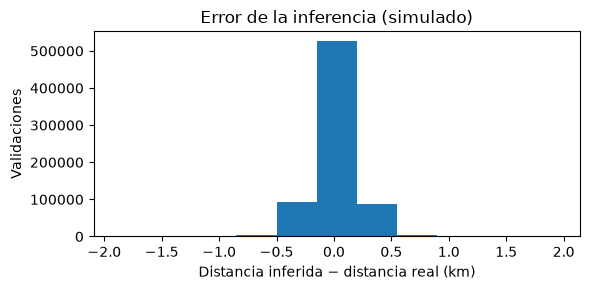

In [3]:
inf = df.d_inf.notna()
err = (df.d_inf - df.d_real)[inf]
sec_real = seccion(df.d_real.to_numpy(), LIM)
print(f'Validaciones con bajada inferida: {inf.mean():.0%}')
print(f'Error de distancia: |error| ≤ 1 parada (350 m) en el {(err.abs() <= .351).mean():.1%} de los casos')
print(f'La sección inferida coincide con la real en el {(df.sec_inf[inf] == sec_real[inf]).mean():.1%} de los casos')
fig, ax = plt.subplots(figsize=(6, 3)); ax.hist(err, bins=np.arange(-1.9, 2, .35), color='tab:blue'); ax.set_xlabel('Distancia inferida − distancia real (km)'); ax.set_ylabel('Validaciones')
ax.set_title('Error de la inferencia (simulado)'); plt.tight_layout(); plt.savefig('../outputs/figures/m05_error_inferencia.png', dpi=150); plt.show()

Los errores son **chicos y simétricos** (una parada de más o de menos). Cuando el viaje cae cerca del borde entre dos secciones, ese error puede cambiar la sección inferida: así aparece ruido en ambas direcciones.

## 3. El indicador: exceso neto de cobros hacia arriba

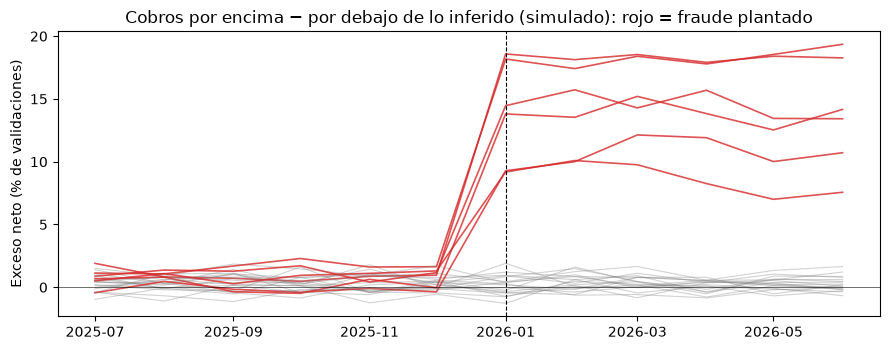

In [4]:
m = resumen_mensual(df, TAR)
m['fraude'] = m.linea.map(fraude)
fig, ax = plt.subplots(figsize=(9, 3.6))
for ln, g in m.groupby('linea'):
    ax.plot(g.mes, g.neto * 100, color='tab:red' if fraude[ln] else 'tab:gray', alpha=.8 if fraude[ln] else .35, lw=1.2 if fraude[ln] else .8)
ax.axvline(pd.Timestamp(INICIO), ls='--', color='k', lw=.8); ax.axhline(0, color='k', lw=.4)
ax.set_ylabel('Exceso neto (% de validaciones)'); ax.set_title('Cobros por encima − por debajo de lo inferido (simulado): rojo = fraude plantado')
plt.tight_layout(); plt.savefig('../outputs/figures/m05_exceso_neto.png', dpi=150); plt.show()

Las líneas sin fraude (gris) oscilan alrededor de un nivel propio: el ruido simétrico, más algún sesgo por los bordes (en una línea corta casi todo es sección 1, que no puede bajar). **Por eso se compara cada línea con sí misma antes y después de la fecha**, no con las demás.

## 4. Test por línea
Para cada línea: ¿los meses posteriores tienen un exceso neto mayor que los previos? Test t de Welch sobre los 6 meses previos y los 6 posteriores. Como se mira a 24 líneas a la vez, usamos la corrección de **Bonferroni** (nivel 5 % ÷ 24): una regla conservadora, fijada de antemano.
Como comparación hacemos el mismo test sobre la **tarifa media** (lo que ve alguien que no puede inferir la bajada).

In [5]:
n = cfg['micro']['n_lineas']
a = test_linea(m, 'neto', INICIO, n).join(fraude); b = test_linea(m, 'tarifa_media', INICIO, n).join(fraude)
filas = []
for nombre, x in [('Con inferencia de bajada (exceso neto)', a), ('Sin inferencia (tarifa media)', b)]:
    filas.append({'enfoque': nombre, 'TP': int((x.marca & x.fraude).sum()), 'FP': int((x.marca & ~x.fraude).sum()), 'FN': int((~x.marca & x.fraude).sum()),
                  'TN': int((~x.marca & ~x.fraude).sum()), 'AUC': round(roc_auc_score(x.fraude, x.t), 3)})
pd.DataFrame(filas).set_index('enfoque')

,TP,FP,FN,TN,AUC
enfoque,,,,,
Con inferencia de bajada (exceso neto),6,0,0,18,1.0
Sin inferencia (tarifa media),6,0,0,18,1.0


Con un fraude del 20 % (de los viajes en secciones 1-2) ambos enfoques lo ven: es un fraude grande. **La diferencia aparece cuando el fraude se achica.**

## 5. Sensibilidad: ¿cuánto fraude hace falta?
Repetimos todo con 30 simulaciones distintas (otra elección de líneas con fraude, otros viajes) para cada magnitud.

In [6]:
mags = [0.005, 0.01, 0.02, 0.03, 0.05, 0.10, 0.20]
r = pd.DataFrame([evaluar_corrida(cfg, largos, mg, s) for mg in mags for s in range(100, 130)])
for k in ('inferencia', 'tarifa_media'):
    r[f'{k}_recall'] = r[f'{k}_tp'] / (r[f'{k}_tp'] + r[f'{k}_fn']); r[f'{k}_fpr'] = r[f'{k}_fp'] / (r[f'{k}_fp'] + r[f'{k}_tn'])
g = r.groupby('magnitud').agg(**{f'{k}_{c}': (f'{k}_{c}', 'mean') for k in ('inferencia', 'tarifa_media') for c in ('recall', 'fpr', 'auc')})
tabla = pd.DataFrame({'recall con inferencia': g.inferencia_recall, 'recall sin inferencia': g.tarifa_media_recall,
                      'AUC con inferencia': g.inferencia_auc, 'AUC sin inferencia': g.tarifa_media_auc}).round(2)
tabla.index = [f'{x:.1%}' for x in tabla.index]; tabla.index.name = 'viajes corridos'
print(f"Falsas alarmas totales: con inferencia {r.inferencia_fp.sum()}, sin inferencia {r.tarifa_media_fp.sum()}, sobre {int((r.inferencia_fp + r.inferencia_tn).sum()):,} líneas inocentes evaluadas")
tabla

Falsas alarmas totales: con inferencia 0, sin inferencia 14, sobre 3,780 líneas inocentes evaluadas


,recall con inferencia,recall sin inferencia,AUC con inferencia,AUC sin inferencia
viajes corridos,,,,
0.5%,0.01,0.00,0.74,0.60
1.0%,0.13,0.01,0.89,0.69
2.0%,0.57,0.03,0.98,0.82
3.0%,0.81,0.11,1.00,0.89
5.0%,0.97,0.39,1.00,0.96
10.0%,1.00,0.79,1.00,0.99
20.0%,1.00,0.99,1.00,1.00


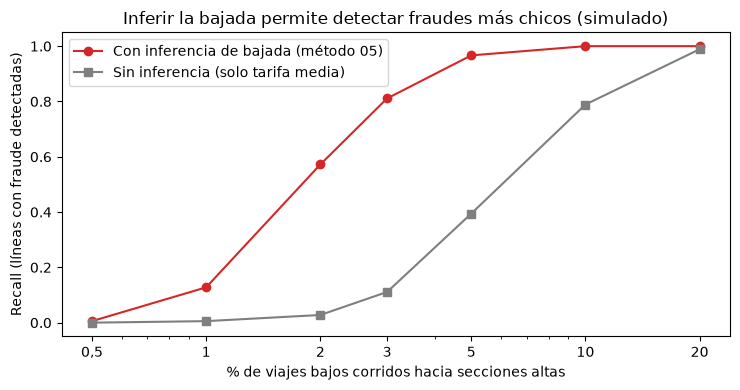

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(g.index * 100, g.inferencia_recall, 'o-', color='tab:red', label='Con inferencia de bajada (método 05)')
ax.plot(g.index * 100, g.tarifa_media_recall, 's-', color='tab:gray', label='Sin inferencia (solo tarifa media)')
ax.set_xscale('log'); ax.set_xticks([.5, 1, 2, 3, 5, 10, 20], ['0,5', '1', '2', '3', '5', '10', '20'])
ax.set_xlabel('% de viajes bajos corridos hacia secciones altas'); ax.set_ylabel('Recall (líneas con fraude detectadas)'); ax.legend(); ax.set_title('Inferir la bajada permite detectar fraudes más chicos (simulado)')
plt.tight_layout(); plt.savefig('../outputs/figures/m05_sensibilidad.png', dpi=150); plt.show()

**Lectura:** inferir la bajada permite detectar el fraude con **bastante menos magnitud**: el 50 % de las líneas se detecta con ~2 % de viajes corridos, contra ~6-7 % si solo se mira la tarifa media (unas 3 veces menos), y, en el escenario base, sin falsas alarmas con la regla conservadora usada (0 sobre 3.780 líneas inocentes). La razón es intuitiva: compara cada cobro contra el recorrido *real* de esa persona, así que no le importa que cambie la mezcla de viajes cortos y largos de un mes a otro, algo que sí confunde a quien mira solo el promedio.

### ¿Cuánto de esta ventaja depende de un supuesto mío?
La ventaja sobre la tarifa media viene de que ésta se mueve mes a mes por la **mezcla de viajes** (algunos meses se viaja más lejos), y eso se confunde con el fraude. Ese ruido mensual (`ruido_mes_sd`) se fijó en 3 % (un supuesto del autor). Veamos qué pasa con otros valores, incluso cero:

In [8]:
filas = []
for sd in (0.0, 0.01, 0.03, 0.06):
    c2 = cargar_config(); c2['micro']['ruido_mes_sd'] = sd
    for mg in (0.02, 0.05):
        x = pd.DataFrame([evaluar_corrida(c2, largos, mg, s) for s in range(100, 130)])
        filas.append({'ruido mensual': f'{sd:.0%}', 'viajes corridos': f'{mg:.0%}',
                      'recall con inferencia': round(x.inferencia_tp.sum() / (x.inferencia_tp + x.inferencia_fn).sum(), 2),
                      'recall sin inferencia': round(x.tarifa_media_tp.sum() / (x.tarifa_media_tp + x.tarifa_media_fn).sum(), 2),
                      'falsas alarmas (con / sin)': f'{int(x.inferencia_fp.sum())} / {int(x.tarifa_media_fp.sum())}'})
pd.DataFrame(filas)

,ruido mensual,viajes corridos,recall con inferencia,recall sin inferencia,falsas alarmas (con / sin)
0,0%,2%,0.72,0.17,2 / 1
1,0%,5%,0.99,0.74,2 / 1
2,1%,2%,0.69,0.17,1 / 1
3,1%,5%,0.99,0.73,1 / 1
4,3%,2%,0.57,0.03,0 / 2
5,3%,5%,0.97,0.39,0 / 2
6,6%,2%,0.48,0.01,4 / 0
7,6%,5%,0.93,0.04,4 / 0


**Lectura:** aun sin ningún ruido de mezcla, inferir la bajada detecta mucho más (72 % contra 17 % con 2 % de viajes corridos). Con más ruido la brecha se agranda, porque la inferencia compara contra el recorrido real de cada viaje y no le afecta la mezcla.
Las falsas alarmas son pocas en todos los casos (sobre 540 líneas inocentes por fila: 30 simulaciones × 18) y no siguen un patrón claro; con 6 % de ruido la inferencia llega a 4. **Pero el tamaño exacto de la ventaja depende de supuestos de la simulación**, no es una medida del mundo real.

## 6. ¿Y el perjuicio?
El exceso medio por validación (cobrado menos inferido), restado el de los meses previos, extrapolado a todas las validaciones del período, estima el sobrecobro de las líneas marcadas.

In [9]:
r['error_rel'] = r.sobrecobro_est / r.sobrecobro_real_marcadas - 1
r.groupby('magnitud').agg(estimado=('sobrecobro_est', 'mean'), real_en_marcadas=('sobrecobro_real_marcadas', 'mean'), error_relativo=('error_rel', 'mean')).round(3).rename_axis('viajes corridos')

,estimado,real_en_marcadas,error_relativo
viajes corridos,,,
0.005,1.476,0.746,0.980
0.010,37.174,30.888,0.225
0.020,269.339,257.894,0.043
0.030,524.656,517.633,0.013
0.050,973.878,970.527,0.003
0.100,1975.216,1971.741,0.001
0.200,3946.705,3942.095,0.001


A partir de ~3 % el sobrecobro estimado queda a pocos puntos del real. Con magnitudes más chicas el método detecta pocas líneas y la estimación es ruidosa.
(Unidades: "tarifa de sección 1 × validación", sobre las 24 líneas simuladas; solo sirve para comparar estimado contra real.)

In [10]:
m.to_parquet('../data/processed/micro_mensual.parquet'); r.to_parquet('../data/processed/res_m05_barrido.parquet')

## Qué datos reales harían falta
Este es el método más poderoso, y también el que más datos exige. Requeriría, **para un conjunto de líneas y días**:
- identificador de tarjeta **enmascarado** (sin posibilidad de vincularlo a personas),
- fecha y hora (se puede redondear a la hora),
- línea y posición geográfica de cada validación,
- **sección o monto efectivamente cobrado**.

Esto es sensible porque son datos de movilidad individual (aunque anonimizados). Una solicitud de acceso razonable pediría una muestra acotada, con tarjetas enmascaradas y tiempos agregados, o plantearía que **el propio organismo** corra el análisis y entregue solo los resultados agregados. Ver `docs/pedido_acceso.md`.

## Limitaciones (importantes)
- **Es una cota optimista.** El modelo es unidimensional: cada tarjeta usa siempre **la misma línea** y no hay trasbordos, ni recorridos que se crucen o hagan un lazo, ni tarjetas compartidas. En la realidad, atribuir la bajada es bastante más difícil.
- **Pérdida de datos al azar.** En la realidad las validaciones sin inferir pueden no ser aleatorias (por ejemplo, ciertos recorridos o franjas horarias), y eso sesga.
- **Mismo mecanismo de fraude en la simulación y en la detección:** un corrimiento fijo desde una fecha. Un fraude gradual, o que dependa del chofer o del horario, cambiaría la sensibilidad.
- **Solo 24 líneas y 6 con fraude (25 %)**, una proporción mayor que en el resto del proyecto, para tener casos suficientes. Las 30 simulaciones de la sección 5 varían qué líneas tienen fraude, pero comparten el mismo modelo.
- **No es comparable uno a uno con los métodos 01-04:** esta simulación tiene otra estructura (microdatos, 12 meses, 24 líneas), así que la comparación vale en dirección y orden de magnitud, no en los números exactos.
- **Un hallazgo con este método seguiría siendo una anomalía a revisar:** una diferencia entre la sección cobrada y la inferida puede tener explicaciones legítimas que el modelo no ve.